# 05 · Features y baselines
1. Catálogo de features y decisiones de diseño.
2. Regla anti-fuga y su verificación empírica (incluyendo una fuga deliberada para comprobar que la prueba la detecta).
3. Baselines con la misma información que el modelo y esquema de validación walk-forward.
4. Qué debe superar el modelo de la Fase 3.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'

from src.data.load import load_transactions, load_stores, load_calendar
from src.data.preprocess import build_panel
from src.features.engineering import FeatureConfig, build_features, CALENDAR_FEATURES, KEY
from src.models.backtest import FOLDS, evaluate, evaluate_by
from src.models.baselines import BASELINES, run_baselines
plt.rcParams.update({'figure.figsize': (10, 3.4), 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 150, 'display.max_columns', 30, 'display.float_format', '{:,.3f}'.format)
t, s, c = load_transactions(), load_stores(), load_calendar()
p = build_panel(t, s, c)
cfg = FeatureConfig(horizon=14); F = build_features(p, cfg)
print(f'horizonte {cfg.horizon} → base_lag {cfg.base_lag} | rezagos estacionales {cfg.seasonal_lags} | {len(cfg.feature_columns())} features | {F.shape[0]:,} filas, elegibles {int(F.eligible.sum()):,}')

horizonte 14 → base_lag 14 | rezagos estacionales [14, 21, 28, 35] | 30 features | 204,000 filas, elegibles 190,998


## 1. Catálogo de features

In [2]:
cols = cfg.feature_columns()
groups = {'Calendario': CALENDAR_FEATURES, 'Historia del target (log)': [x for x in cols if x.startswith(('lag_', 'same_dow', 'roll_', 'trend'))],
          'Promoción': [x for x in cols if 'promo' in x], 'Tienda / serie': ['category', 'store_format', 'socioeconomic_level']}
cat = pd.DataFrame([(g, len(v), ', '.join(v)) for g, v in groups.items()], columns=['grupo', 'n', 'variables']).set_index('grupo')
assert sum(cat.n) == len(cols); print(cat.to_string(max_colwidth=130))
nan = (F[cols].isna().mean() * 100).round(2); print('\n% de NaN (solo variables con nulos):'); print(nan[nan > 0].to_string())

                            n                                                                                                                          variables
grupo                                                                                                                                                           
Calendario                 16  day_of_week, day_of_month, is_weekend, is_official_holiday, is_payday, is_navidad_season, is_buen_fin, is_semana_santa, days_t...
Historia del target (log)   9                             lag_14d, lag_21d, lag_28d, lag_35d, same_dow_mean, roll_mean_7, roll_mean_28, roll_std_28, trend_ratio
Promoción                   2                                                                                                      has_promotion, promo_share_28
Tienda / serie              3                                                                                        category, store_format, socioeconomic_level

% de NaN (solo variables con nulo

**Decisiones de diseño**
- **Escala:** los features de historia del target están en logaritmos (la escala del modelo); las columnas `base_*` (baselines) están en niveles (MXN).
- **Rezagos por fecha** sobre el panel completo, no por posición de fila. Ventanas con `min_periods` explícito (50 %) y sin rellenar faltantes: una fila ausente deja el rezago correspondiente en NaN.
- **Sin `month`, `quarter`, `week_of_year` ni `store_id`.** Con 14 meses cada valor anual se observa una sola vez y el modelo lo usaría como índice de tiempo. El nivel de cada serie entra por sus rezagos, lo que evita memorizar tiendas. Se verificará por ablación en la Fase 3.
- **Variables de tienda:** solo `store_format` y `socioeconomic_level` (ordinal C < C+ < B < A/B); región, farmacia, gasolinera y tamaño no aportan una vez conocido el formato (notebook 02). `FeatureConfig.store_features` permite añadirlas para la ablación.
- **Quincena por regla** (día 15 y último del mes), con distancias en ambos sentidos. `is_official_holiday` separa los festivos del Buen Fin, que `is_holiday` mezcla.
- **Navidad:** `days_to_christmas` con signo (−14 a 60) distingue la rampa de nov–dic de la caída posterior de enero, que `is_navidad_season` (15-dic a 6-ene) no separa.
- **Buen Fin:** `buen_fin_day`, `days_to_buen_fin` y `days_since_buen_fin`, repitiendo el evento ±364 días (mismo día de la semana) para no tener NaN fuera del año observado. Describen *cuándo* ocurre, no su magnitud: con una sola ocurrencia el modelo no puede aprenderla.
- **Promoción planeada:** `has_promotion` del día *t* se asume conocida al pronosticar (decisión del proyecto); `promo_share_28` solo usa historia. Como el efecto en monto es ≈ 0, el riesgo de este supuesto es bajo.

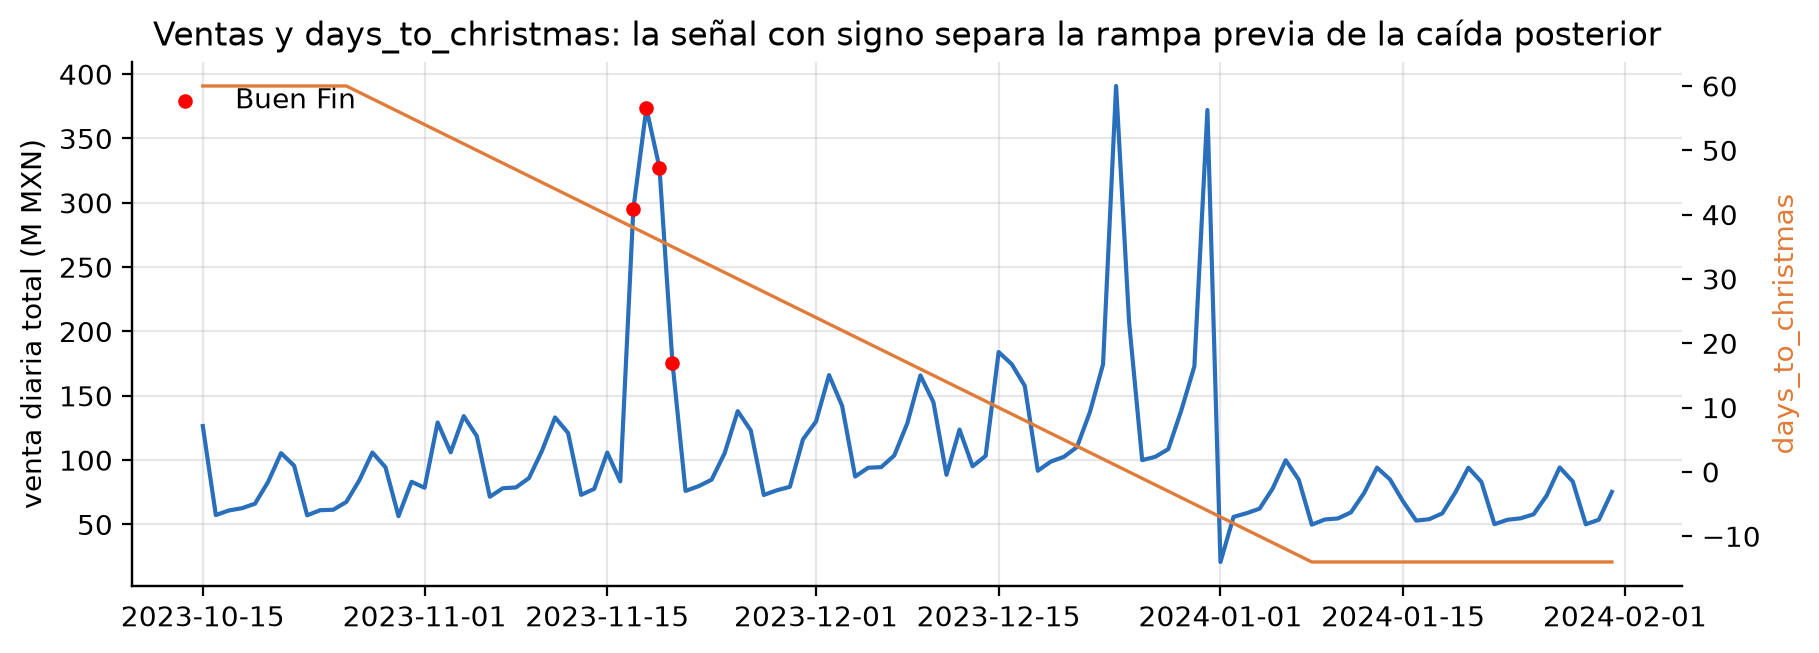

In [3]:
d = F.drop_duplicates('date').set_index('date'); tot = p.groupby('date').amount_total.sum() / 1e6
fig, ax = plt.subplots(); sub = tot['2023-10-15':'2024-01-31']; ax.plot(sub.index, sub.values, color='#2a6fbb'); ax.set_ylabel('venta diaria total (M MXN)')
ax2 = ax.twinx(); ax2.plot(sub.index, d.loc[sub.index, 'days_to_christmas'], color='#e07b39', lw=1.2); ax2.set_ylabel('days_to_christmas', color='#e07b39'); ax2.grid(False)
bf = d.index[d.buen_fin_day > 0]; ax.scatter(bf, tot.reindex(bf), color='red', s=18, zorder=3, label='Buen Fin'); ax.legend(frameon=False, loc='upper left')
ax.set_title('Ventas y days_to_christmas: la señal con signo separa la rampa previa de la caída posterior'); plt.show()

## 2. Regla anti-fuga
Todo feature derivado del target para la fecha *t* usa solo datos con fecha ≤ *t − base_lag*, donde `base_lag` es el múltiplo de 7 más pequeño ≥ horizonte. Con múltiplos de 7 los rezagos caen en el mismo día de la semana.

**Verificación empírica:** se altera el target posterior a un corte *C* y se comprueba que ningún feature de las fechas ≤ *C + base_lag* cambia. Para comprobar que la prueba no es vacía, se repite con una fuga deliberada (rezagos de 7 días con horizonte 14): debe detectarla.

In [4]:
def leak_report(cfg_, cut='2023-09-30'):
    cut = pd.Timestamp(cut); base = build_features(p, cfg_)
    alt = p.copy(); m = alt.date > cut; alt.loc[m, 'amount_total'] *= np.random.default_rng(0).uniform(.3, 3, m.sum())
    new = build_features(alt, cfg_); keep = base.date <= cut + pd.Timedelta(days=cfg_.horizon)
    feats = cfg_.feature_columns() + [x for x in base.columns if x.startswith('base_')]
    return [x for x in feats if not base.loc[keep, x].fillna(-9e9).equals(new.loc[keep, x].fillna(-9e9))]
class Leaky(FeatureConfig):                      # fuga deliberada: rezagos de 7 días con horizonte 14
    base_lag = property(lambda self: 7)
for h in (7, 14, 28):
    print(f'horizonte {h:2d} (base_lag {FeatureConfig(horizon=h).base_lag:2d}) · features que cambian antes de C + horizonte: {leak_report(FeatureConfig(horizon=h)) or "ninguno ✓"}')
print('fuga deliberada (base_lag 7, horizonte 14) →', leak_report(Leaky(horizon=14)), '← detectada')

horizonte  7 (base_lag  7) · features que cambian antes de C + horizonte: ninguno ✓
horizonte 14 (base_lag 14) · features que cambian antes de C + horizonte: ninguno ✓
horizonte 28 (base_lag 28) · features que cambian antes de C + horizonte: ninguno ✓
fuga deliberada (base_lag 7, horizonte 14) → ['lag_7d', 'same_dow_mean', 'roll_mean_7', 'roll_mean_28', 'roll_std_28', 'trend_ratio', 'base_snaive', 'base_sma4', 'base_ma28'] ← detectada


Estas mismas pruebas viven en `tests/test_features.py` (`uv run pytest`) y se corren con los horizontes 7, 14 y 28. También verifican que ningún feature sea una columna del mismo día (unidades, ticket, efectivo, transacciones) ni `replenishment_signal`, que los rezagos se calculen por fecha y que las filas ausentes queden fuera de entrenamiento y métricas.

## 3. Baselines y esquema de validación
Con **horizonte directo** el pronóstico de la fecha *t* usa información hasta *t − base_lag*. Los baselines usan esa misma información:

| Baseline | Definición |
|---|---|
| `snaive` | valor del mismo día de la semana hace `base_lag` días |
| `sma4` | promedio de los últimos 4 mismos días de la semana (`base_lag`, +7, +14, +21) |
| `ma28` | promedio móvil de 28 días terminado en *t − base_lag* |

**Folds walk-forward** (`src/models/backtest.py`): ventanas de prueba de semanas completas (lunes a domingo); el modelo de cada fold se entrenaría solo con fechas ≤ inicio − horizonte. La meta se mide en **tienda × categoría × semana** (semanas con los 7 días). Los tipos de fold se definieron por regla *antes* de ver resultados: **regular** (ni la prueba ni los rezagos de 14–35 días tocan Buen Fin o Navidad), **evento** (la prueba contiene un evento) y **post_evento** (la prueba es normal pero sus rezagos caen sobre un evento).

In [5]:
print(pd.DataFrame([(f.name, f.kind, f.start, f.end, f'{((pd.Timestamp(f.end) - pd.Timestamp(f.start)).days + 1) // 7} sem.') for f in FOLDS], columns=['fold', 'tipo', 'inicio', 'fin', 'duración']).to_string(index=False))
B = run_baselines(F); sw = B[B.nivel == 'serie × semana']
W = sw.pivot_table(index=['tipo', 'fold'], columns='modelo', values='wape') * 100; Bi = sw.pivot_table(index=['tipo', 'fold'], columns='modelo', values='bias') * 100
print('\nWAPE % (tienda × categoría × semana) y sesgo %, horizonte 14:'); W.round(1).join(Bi.round(1), rsuffix=' (sesgo)')

             fold        tipo     inicio        fin duración
semana_santa_2023     regular 2023-03-27 2023-04-23   4 sem.
     may_jun_2023     regular 2023-05-29 2023-06-25   4 sem.
         sep_2023     regular 2023-09-04 2023-10-01   4 sem.
         oct_2023     regular 2023-10-02 2023-10-29   4 sem.
    buen_fin_2023      evento 2023-11-06 2023-12-03   4 sem.
     navidad_2023      evento 2023-12-11 2024-01-07   4 sem.
post_navidad_2024 post_evento 2024-01-08 2024-02-11   5 sem.
         feb_2024     regular 2024-02-12 2024-02-25   2 sem.

WAPE % (tienda × categoría × semana) y sesgo %, horizonte 14:


modelo                          ma28   sma4  snaive  ma28 (sesgo)  sma4 (sesgo)  snaive (sesgo)
tipo        fold                                                                               
evento      buen_fin_2023     33.400 31.500  40.200       -33.300       -28.900          -9.200
            navidad_2023      25.500 29.200  36.800        -4.100        -3.600          -1.600
post_evento post_navidad_2024 71.700 62.900  37.800        71.700        61.700          28.800
regular     feb_2024           7.800  7.800   9.000        -4.300        -3.900          -3.100
            may_jun_2023       8.200  8.100   8.900        -5.600        -5.400          -3.000
            oct_2023           8.100  8.000   9.300         4.500         4.300           2.800
            semana_santa_2023  8.700  8.700   9.700        -2.700        -2.400          -3.300
            sep_2023           8.100  8.100   9.300         2.800         2.800           1.700

In [6]:
reg = sw[sw.tipo == 'regular'].groupby('modelo').apply(lambda g: pd.Series({'WAPE % (media de folds regulares)': g.wape.mean() * 100, 'WAPE % mín': g.wape.min() * 100, 'WAPE % máx': g.wape.max() * 100, 'MAPE %': g.mape.mean() * 100, 'sesgo %': g.bias.mean() * 100}))
print('Folds regulares:'); print(reg.round(1).to_string())
niv = B[(B.tipo == 'regular') & (B.modelo == 'sma4')].groupby('nivel').wape.mean().mul(100).round(1).reindex(['serie × día', 'serie × semana', 'tienda × semana', 'total × semana'])
print('\nsma4 en folds regulares por nivel de agregación (WAPE %), para comparar con los pisos de ruido del notebook 02 (15.6 / 6.5 / 3.4 / 2.1):'); print(niv.to_string())

Folds regulares:
        WAPE % (media de folds regulares)  WAPE % mín  WAPE % máx  MAPE %  sesgo %
modelo                                                                            
ma28                                8.200       7.800       8.700   8.200   -1.000
sma4                                8.200       7.800       8.700   8.100   -0.900
snaive                              9.200       8.900       9.700   9.200   -1.000

sma4 en folds regulares por nivel de agregación (WAPE %), para comparar con los pisos de ruido del notebook 02 (15.6 / 6.5 / 3.4 / 2.1):
nivel
serie × día       19.200
serie × semana     8.200
tienda × semana    5.400
total × semana     4.800


In [7]:
test_reg = pd.concat([F[f.test_mask(F.date) & F.eligible] for f in FOLDS if f.kind == 'regular'])
seg = {by: evaluate_by(test_reg, 'base_sma4', by)[['wape', 'bias']].mul(100).round(1) for by in ['category', 'store_format', 'region']}
print('sma4 en folds regulares, WAPE % y sesgo % por segmento (tienda × categoría × semana):'); pd.concat(seg, names=['segmento', 'valor'])

sma4 en folds regulares, WAPE % y sesgo % por segmento (tienda × categoría × semana):


wape   bias
segmento     valor                        
category     Abarrotes        8.100 -0.600
             Bebidas          8.200 -0.600
             Cuidado_Personal 8.400 -0.800
             Electronica      8.100 -0.400
             Hogar            8.100 -0.500
             Ropa             8.400 -0.300
store_format Bodega           8.100 -0.400
             Express          8.000 -0.400
             Supercenter      8.300 -0.700
region       Centro           8.200 -0.000
             Norte            8.100 -0.700
             Occidente        8.200 -0.700
             Oriente          8.300 -0.400
             Sur              8.200 -0.600

**Lectura.**
- **Periodos regulares:** `sma4` y `ma28` quedan en **8.2 % de WAPE semanal** (rango por fold 7.8 %–8.7 %), `snaive` en 9.2 %. El sesgo medio es pequeño (≈ −1 %) pero cambia de signo entre folds (+2.8 % y +4.3 % en sep–oct, −5.4 % en may–jun): el nivel común de la cadena deriva durante el año y los baselines van un paso atrás. El baseline ya cumple una meta de 10 %: **el listón del modelo es `sma4`, no el 10 %**.
- **Margen real:** el piso de ruido a este nivel es ≈ 6.5 % (notebook 02), así que el modelo solo puede mejorar ≈ 1.7 puntos en periodos regulares. A nivel serie-día `sma4` tiene 19.2 % frente a un piso de 15.6 %.
- **Sin segmentos problemáticos:** el WAPE de `sma4` es 8.0 %–8.4 % en todas las categorías, formatos y regiones.
- **Eventos:** todos los baselines fallan (WAPE 25 %–40 %). En Buen Fin sub-pronostican (sesgo −29 % a −33 %) porque el evento nunca se había visto.
- **Post-evento (enero–febrero tras Navidad):** `sma4` llega a 62.9 % con **sesgo +61.7 %** y `ma28` a 71.7 %, porque sus rezagos de 14–35 días caen sobre el pico de diciembre y proyectan demanda que ya no existe (riesgo de exceso de inventario). `snaive`, que usa un solo día de referencia, llega a 37.8 %. Es la debilidad más grande de los baselines y la razón de reportar este tipo de fold aparte.

### 3.1 Sensibilidad al horizonte
Si el horizonte fuera 28 días en lugar de 14, los baselines pierden información reciente:

In [8]:
B28 = run_baselines(build_features(p, FeatureConfig(horizon=28))); s28 = B28[B28.nivel == 'serie × semana'].pivot_table(index='modelo', columns='tipo', values='wape').mul(100)
s14 = sw.pivot_table(index='modelo', columns='tipo', values='wape').mul(100)
pd.concat({'horizonte 14': s14, 'horizonte 28': s28}, axis=1).round(1)

horizonte 14                     horizonte 28                    
tipo         evento post_evento regular       evento post_evento regular
modelo                                                                  
ma28         29.400      71.700   8.200       36.200      89.500  13.600
sma4         30.400      62.900   8.200       34.200      87.200  10.600
snaive       38.500      37.800   9.200       38.100      79.900   9.900

**Lectura.** Con horizonte 28 los baselines empeoran en todos los regímenes: en periodos regulares `sma4` pasa de 8.2 % a **10.6 %** (ya no cumpliría una meta de 10 %), en eventos de 30.4 % a 34.2 % y en post-evento de 62.9 % a 87.2 %. Esto respalda usar **14 días como horizonte principal**, con 28 como análisis de sensibilidad (`FeatureConfig(horizon=28)`).

## Conclusiones y criterios para la Fase 3
| Tema | Resultado |
|---|---|
| Features | 30 columnas de modelo (calendario 16, historia del target 9, promoción 2, serie 3); sin `month`/`week_of_year`/`store_id`; sin variables del mismo día ni `replenishment_signal` |
| Anti-fuga | Verificada empíricamente en horizontes 7, 14 y 28 (`tests/test_features.py`); una fuga deliberada se detecta |
| Baseline a superar | `sma4`: 8.2 % de WAPE semanal en folds regulares (piso de ruido ≈ 6.5 %) |
| Eventos y post-evento | Los baselines fallan (25 %–40 % y 38 %–72 %); se reportan por separado |

**Criterios de éxito para el modelo (Fase 3)**
1. Mejorar a `sma4` en folds regulares (WAPE semanal serie × tienda × categoría), con significancia estadística (Diebold–Mariano o bootstrap por bloques) y sin sesgo sistemático.
2. En eventos y post-evento, no ser peor que el mejor baseline y reportar el sesgo; un modelo que depende de calendario y rezagos no puede aprender la magnitud de un evento visto una sola vez.
3. Un WAPE serie-día por debajo de ≈ 15 % se trata como alarma de fuga.
4. Probar por ablación: variables de calendario anual (`month`), atributos de tienda adicionales y `has_promotion`.